# EPA 라벨 조합 통합 비교
저장된 동일 실행 ID의 skin·eye 결과 24개(CatBoost 제외)만 읽고 검증합니다. 학습을 다시 실행하거나 다른 실행 결과를 섞지 않습니다. 이전 완료 결과의 재사용 근거는 scope_manifest.json과 각 endpoint의 reuse_lineage.json에 기록됩니다.

In [1]:
import os, sys
from pathlib import Path
OUTPUT_ROOT = Path(r'C:/Users/DS/COS/최종/label 조합 변경')
sys.path.insert(0, str(OUTPUT_ROOT))
from epa_experiment_utils import compare_run
RUN_ID = os.environ.setdefault('EPA_RUN_ID', 'epa-production-20261106-no-catboost')
{'run_id':RUN_ID,'output_root':str(OUTPUT_ROOT),'expected_combinations':24}

{'run_id': 'epa-production-20261106-no-catboost',
 'output_root': 'C:\\Users\\DS\\COS\\최종\\label 조합 변경',
 'expected_combinations': 24}

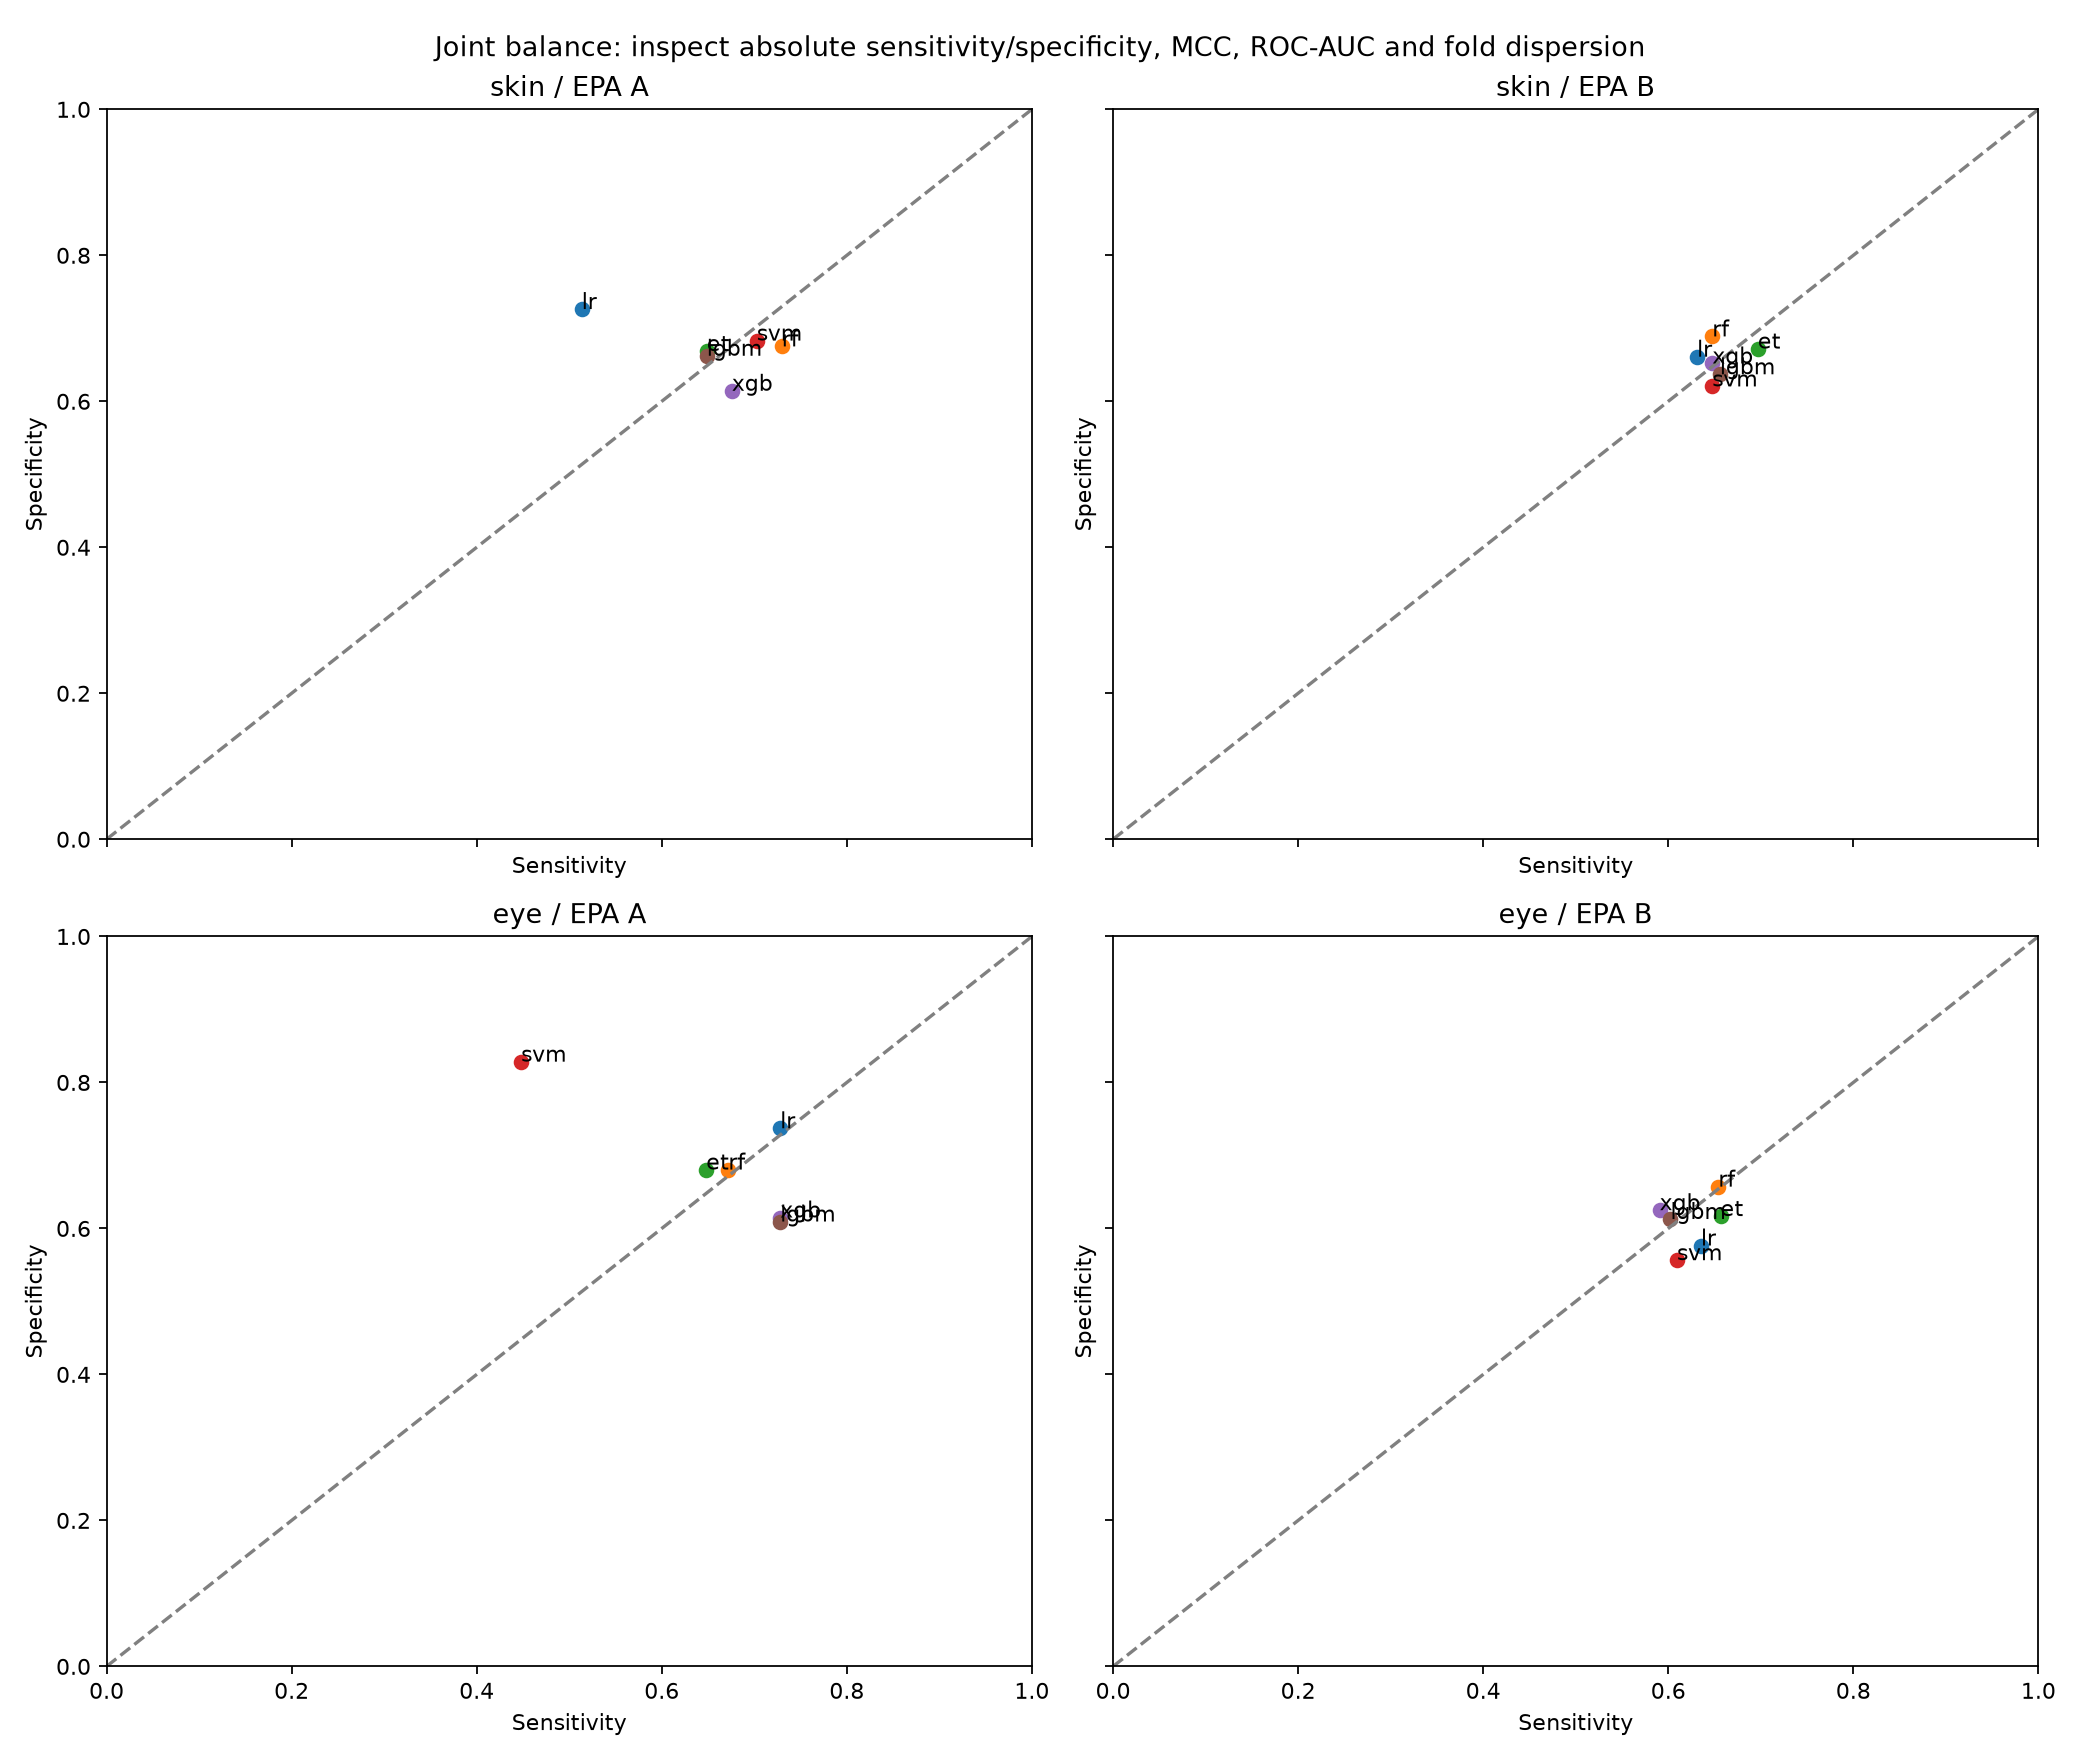

,endpoint,label,model,sensitivity,specificity,MCC,ROC-AUC,abs_gap,PR-AUC,precision,F1,balanced_accuracy,positive_count,negative_count,confusion_matrix,sensitivity_std,specificity_std,MCC_std,ROC-AUC_std
0,skin,A,lr,0.513514,0.726400,0.121828,0.636130,0.212886,0.156860,0.100000,0.167401,0.619957,37,625,"[[454, 171], [18, 19]]",0.093984,0.083599,0.053901,0.080079
1,skin,A,rf,0.729730,0.675200,0.195351,0.755265,0.054530,0.218571,0.117391,0.202247,0.702465,37,625,"[[422, 203], [10, 27]]",0.136230,0.082482,0.038645,0.045088
2,skin,A,et,0.648649,0.668800,0.152992,0.689081,0.020151,0.188114,0.103896,0.179104,0.658724,37,625,"[[418, 207], [13, 24]]",0.096989,0.063649,0.038178,0.039639
3,skin,A,svm,0.702703,0.683200,0.187352,0.728022,0.019503,0.213278,0.116071,0.199234,0.692951,37,625,"[[427, 198], [11, 26]]",0.120923,0.030252,0.066266,0.074581
4,skin,A,xgb,0.675676,0.614400,0.135914,0.698573,0.061276,0.193713,0.093985,0.165017,0.645038,37,625,"[[384, 241], [12, 25]]",0.209165,0.064844,0.092596,0.075059
5,skin,A,lgbm,0.648649,0.662400,0.149321,0.683265,0.013751,0.204207,0.102128,0.176471,0.655524,37,625,"[[414, 211], [13, 24]]",0.096989,0.033178,0.044666,0.098424
6,skin,B,lr,0.631148,0.661111,0.232030,0.703294,0.029964,0.332980,0.296154,0.403141,0.646129,122,540,"[[357, 183], [45, 77]]",0.105698,0.088956,0.037107,0.025853
7,skin,B,rf,0.647541,0.688889,0.269711,0.727580,0.041348,0.380774,0.319838,0.428184,0.668215,122,540,"[[372, 168], [43, 79]]",0.056363,0.072198,0.073163,0.031362
8,skin,B,et,0.696721,0.672222,0.292520,0.725804,0.024499,0.367068,0.324427,0.442708,0.684472,122,540,"[[363, 177], [37, 85]]",0.119195,0.066319,0.076213,0.026992
9,skin,B,svm,0.647541,0.620370,0.209876,0.652444,0.027171,0.307236,0.278169,0.389163,0.633956,122,540,"[[335, 205], [43, 79]]",0.093101,0.065473,0.046923,0.026361


In [2]:
from IPython.utils.capture import capture_output
from IPython.display import Image, display
with capture_output(stdout=False, stderr=False):
    comparison = compare_run(output_root=OUTPUT_ROOT, run_id=RUN_ID)
import pandas as pd
from epa_experiment_utils import completed_pointer, load_record
run_root = OUTPUT_ROOT / 'runs' / RUN_ID
display(Image(filename=str(run_root / 'sensitivity_specificity.png')))
rows = []
for endpoint in ('skin', 'eye'):
    pointer = completed_pointer(run_root, endpoint)
    rows.extend(load_record(Path(pointer['output_dir']) / 'report.json', pointer['identity']))
columns = ['endpoint', 'label', 'model', 'sensitivity', 'specificity', 'MCC', 'ROC-AUC',
           'abs_gap', 'PR-AUC', 'precision', 'F1', 'balanced_accuracy',
           'positive_count', 'negative_count', 'confusion_matrix',
           'sensitivity_std', 'specificity_std', 'MCC_std', 'ROC-AUC_std']
full_comparison = pd.DataFrame(rows)
for metric in ('sensitivity', 'specificity', 'MCC', 'ROC-AUC'):
    full_comparison[metric + '_std'] = full_comparison['fold_dispersion'].map(lambda values: values[metric])
full_comparison = full_comparison[columns]
csv_path = run_root / 'comparison_all_metrics.csv'
csv_content = full_comparison.to_csv(index=False, lineterminator='\n')
if csv_path.exists():
    if csv_path.read_text(encoding='utf-8-sig') != csv_content:
        raise ValueError('Existing full-metric comparison differs; refusing to overwrite')
else:
    csv_path.write_text(csv_content, encoding='utf-8-sig', newline='')
full_comparison

## 균형 중심 해석
PR-AUC는 Average Precision(AP)이며, 각 `_std` 열은 외부 5-fold의 표본 표준편차(ddof=1)입니다. 표준편차는 신뢰구간이나 통계적 유의성을 뜻하지 않습니다.
SVM의 fold별 margin은 공통 확률 척도로 보정되지 않았으므로 pooled ROC-AUC·PR-AUC는 기술적 순위 요약으로만 해석합니다.
sensitivity, specificity, MCC, ROC-AUC 네 핵심 열을 나란히 확인합니다. sensitivity와 specificity가 모두 충분히 높은지와 그 차이 및 fold별 변동성을 함께 봅니다. 작은 gap만으로 좋은 모델이라 판단하지 않고, 단일 ROC-AUC/MCC 최고값을 근거로 우승 모델을 선언하지 않습니다. 산점도의 대각선은 두 지표가 같은 위치를 뜻하며 높은 성능 자체를 보장하지 않습니다. A/B 타깃 정의가 다르므로 수치 차이를 동일 문제의 절대 우열로 해석하지 않습니다.

### 이번 실행에서 관찰한 절충 관계
아래 수치는 pooled OOF 결과를 소수점 세 자리로 표시한 기술적 요약이며, 단일 우승 모델이나 통계적 유의성을 선언하지 않습니다.

- **Skin A:** RF는 sensitivity/specificity **0.730/0.675**, MCC **0.195**, ROC-AUC **0.755**였고, SVM은 **0.703/0.683**, **0.187**, **0.728**이었습니다. RF의 sensitivity가 높지만 specificity의 fold 표준편차는 **0.082**로 SVM의 **0.030**보다 컸습니다. LGBM의 작은 gap **0.014**만으로 더 좋은 모델이라 판단할 수 없습니다(MCC **0.149**). 양성은 37개로 적어 변동성과 낮은 precision도 함께 확인해야 합니다.
- **Skin B:** Extra Trees는 **0.697/0.672**, MCC **0.293**, ROC-AUC **0.726**이었고, RF는 **0.648/0.689**, **0.270**, **0.728**이었습니다. Extra Trees의 sensitivity와 RF의 specificity 사이에 절충이 있으며, sensitivity 표준편차는 각각 **0.119/0.056**으로 안정성도 다릅니다.
- **Eye A:** LR은 **0.728/0.737**, MCC **0.380**, ROC-AUC **0.738**로 두 비율이 가까웠습니다(gap **0.009**). SVM은 **0.448/0.828**, **0.258**, **0.670**으로 specificity에 치우쳤고, sensitivity 표준편차 **0.414**는 LR의 **0.111**보다 컸습니다. 높은 specificity만으로 균형이 좋다고 해석하지 않습니다.
- **Eye B:** RF는 **0.654/0.657**, MCC **0.301**, ROC-AUC **0.656**, LGBM은 **0.602/0.613**, **0.208**, **0.659**였습니다. ROC-AUC가 비슷해도 임계값 기반 균형과 MCC는 다르며, specificity 표준편차는 RF **0.098**, LGBM **0.073**입니다. RF의 매우 작은 gap **0.003**도 두 비율의 절대 수준이 약 0.65라는 사실과 함께 해석해야 합니다.